In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:
rfm = pd.read_csv(
    r"D:\Customer Segmentation Analysis\data\processed\customer_rfm_segments.csv"
)

print("RFM data loaded successfully.")

print(rfm.head())

RFM data loaded successfully.
  CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0     C00001      468          4   1708.39        2        2        4   
1     C00002      601          5   1121.89        1        3        3   
2     C00003       76          2    761.39        4        1        2   
3     C00004       80          5   1362.58        4        3        3   
4     C00005      325          3   1472.60        2        2        3   

   RFM_Score     Customer_Segment  
0        224          Hibernating  
1        133              At Risk  
2        412     Recent Customers  
3        433  Potential Loyalists  
4        223          Hibernating  


In [3]:
# checking

print("Dataset Shape: ", rfm.shape)
print("\nColumn Names: ")
print(rfm.columns)
print("\nMissing Values: ")
print(rfm.isnull().sum())

Dataset Shape:  (6232, 9)

Column Names: 
Index(['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score',
       'M_Score', 'RFM_Score', 'Customer_Segment'],
      dtype='str')

Missing Values: 
CustomerID          0
Recency             0
Frequency           0
Monetary            0
R_Score             0
F_Score             0
M_Score             0
RFM_Score           0
Customer_Segment    0
dtype: int64


In [4]:
# select RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]
print(rfm_features.head())
print("\nFeature Summary: ")
print(rfm_features.describe())

   Recency  Frequency  Monetary
0      468          4   1708.39
1      601          5   1121.89
2       76          2    761.39
3       80          5   1362.58
4      325          3   1472.60

Feature Summary: 
           Recency    Frequency     Monetary
count  6232.000000  6232.000000  6232.000000
mean    310.104140     5.215019  1503.603809
std     303.939159     3.377968  1079.517870
min       1.000000     1.000000    15.360000
25%      82.000000     3.000000   675.675000
50%     211.500000     5.000000  1264.355000
75%     443.000000     7.000000  2117.747500
max    1752.000000    21.000000  7193.040000


In [5]:
# standardizing the RFM features

# initializing standardscaler
scaler = StandardScaler()

# standardize RFM features
rfm_scaled = scaler.fit_transform(rfm_features)

# convert scaled data into dataframe
rfm_scaled = pd.DataFrame(
    rfm_scaled, 
    columns = ["Recency", "Frequency", "Monetary"]
)

print(rfm_scaled.head())

print("\nScaled Feature Summary: ")
print(rfm_scaled.describe())

    Recency  Frequency  Monetary
0  0.519540  -0.359718  0.189717
1  0.957163  -0.063659 -0.353625
2 -0.770295  -0.951838 -0.687597
3 -0.757134  -0.063659 -0.130646
4  0.049013  -0.655778 -0.028722

Scaled Feature Summary: 
            Recency     Frequency      Monetary
count  6.232000e+03  6.232000e+03  6.232000e+03
mean   3.591479e-17  2.280304e-17  1.242766e-16
std    1.000080e+00  1.000080e+00  1.000080e+00
min   -1.017075e+00 -1.247897e+00 -1.378730e+00
25%   -7.505530e-01 -6.557780e-01 -7.670047e-01
50%   -3.244467e-01 -6.365854e-02 -2.216434e-01
75%    4.372800e-01  5.284609e-01  5.689512e-01
max    4.744409e+00  4.673297e+00  5.270772e+00


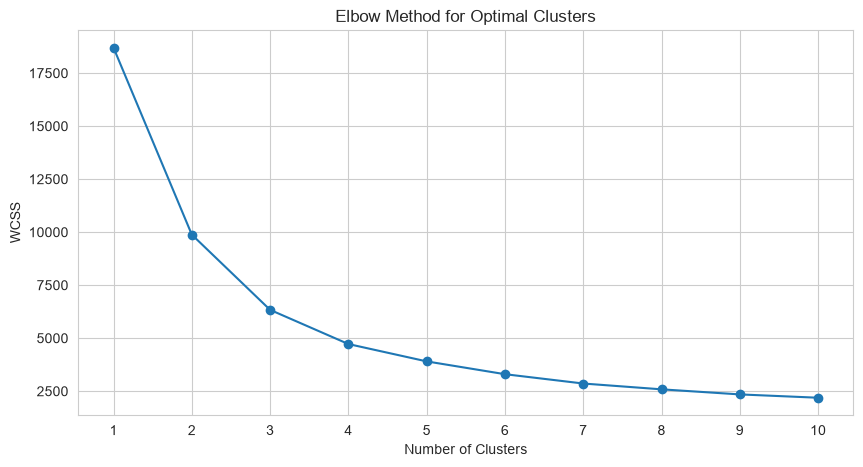

In [7]:
# calculate WCSS for different cluster numbers

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters = i,
        random_state = 42,
        n_init = 10
    )
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# plot elbow method

plt.figure(figsize=(10, 5))

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [8]:
# applying k-means clustering

kmeans = KMeans(
    n_clusters = 3,
    random_state = 42,
    n_init = 10
)

# fit the model and assign cluster labels
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# display
print(rfm[["CustomerID", "Recency", "Frequency",
           "Monetary", "Cluster"]].head(10))

  CustomerID  Recency  Frequency  Monetary  Cluster
0     C00001      468          4   1708.39        1
1     C00002      601          5   1121.89        0
2     C00003       76          2    761.39        1
3     C00004       80          5   1362.58        1
4     C00005      325          3   1472.60        1
5     C00006       60          1     61.45        1
6     C00007       19          6   2086.28        1
7     C00008       58          7   2550.72        2
8     C00009     1008          2    399.96        0
9     C00010      260         11   4116.41        2


In [9]:
# number of customers in each cluster

print("Customer Distribution by Cluster:")
print(rfm["Cluster"].value_counts().sort_index())

Customer Distribution by Cluster:
Cluster
0    1148
1    3409
2    1675
Name: count, dtype: int64


In [10]:
# calculate average RFM valuues for each cluster

cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count = ("CustomerID", "count"),
    Average_Recency = ("Recency", "mean"),
    Average_Frequency = ("Frequency", "mean"),
    Average_Monetary = ("Monetary", "mean")
).round(2)

print(cluster_summary)

         Customer_Count  Average_Recency  Average_Frequency  Average_Monetary
Cluster                                                                      
0                  1148           827.30               2.49            694.71
1                  3409           213.28               3.94           1076.16
2                  1675           152.70               9.67           2927.95


In [12]:
# assign meaningful names to cluster

cluster_names = {
    0: "Dormant Customers",
    1: "Regular Customers",
    2: "High-Value Loyal Customers"
}

rfm["Cluster_Name"] = rfm["Cluster"].map(cluster_names)

# Display customer segments
print(rfm[["CustomerID", "Cluster", "Cluster_Name"]].head(10))

  CustomerID  Cluster                Cluster_Name
0     C00001        1           Regular Customers
1     C00002        0           Dormant Customers
2     C00003        1           Regular Customers
3     C00004        1           Regular Customers
4     C00005        1           Regular Customers
5     C00006        1           Regular Customers
6     C00007        1           Regular Customers
7     C00008        2  High-Value Loyal Customers
8     C00009        0           Dormant Customers
9     C00010        2  High-Value Loyal Customers


In [13]:
# checking final cluster distribution

print(rfm["Cluster_Name"].value_counts())

Cluster_Name
Regular Customers             3409
High-Value Loyal Customers    1675
Dormant Customers             1148
Name: count, dtype: int64


In [15]:
# saving
rfm.to_csv(
    r"D:\Customer Segmentation Analysis\data\processed\customer_kmeans_segments.csv",
    index=False
)

print("K-Means customer segmentation saved.")

K-Means customer segmentation saved.


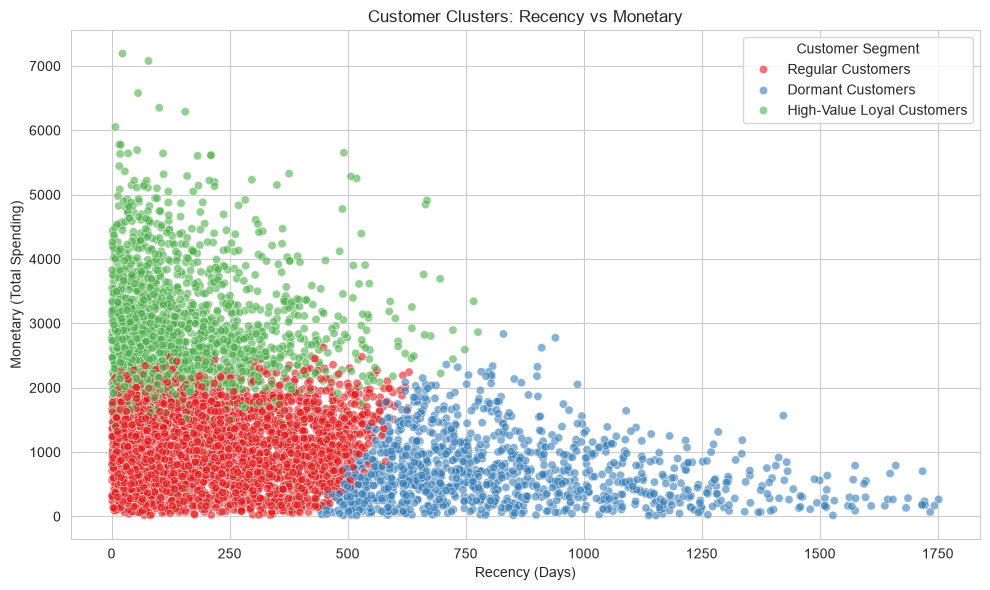

In [19]:
# visualize recency vs monetary

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster_Name",
    palette="Set1",
    alpha=0.6
)

plt.title("Customer Clusters: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary (Total Spending)")
plt.legend(title="Customer Segment")
plt.tight_layout()
plt.savefig(
    r"D:\Customer Segmentation Analysis\outputs\figures\kmeans_recency_monetary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


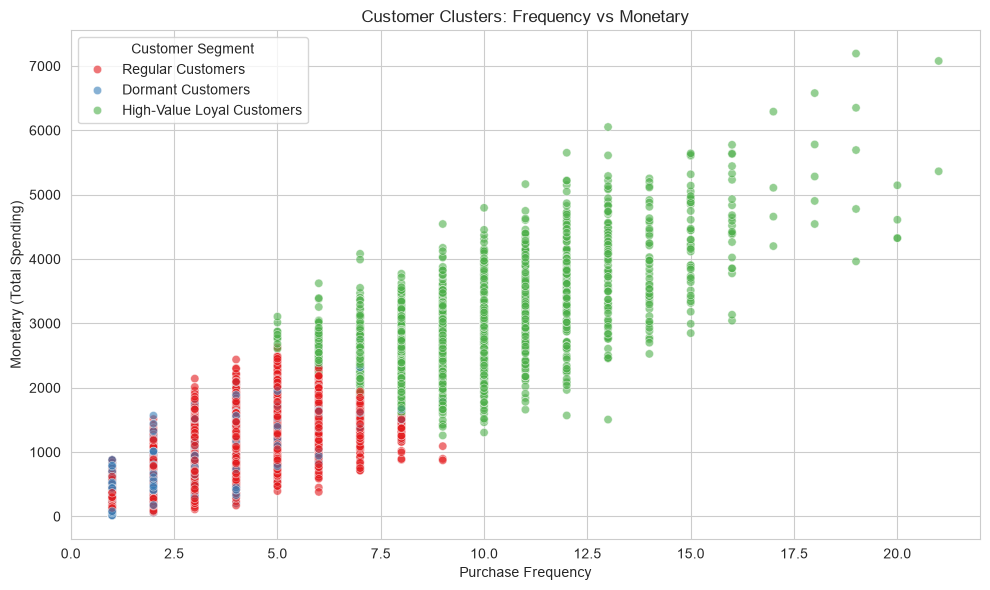

In [20]:
# visualize frequency vs monetary

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster_Name",
    palette="Set1",
    alpha=0.6
)

plt.title("Customer Clusters: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary (Total Spending)")
plt.legend(title="Customer Segment")
plt.tight_layout()
plt.savefig(
    r"D:\Customer Segmentation Analysis\outputs\figures\kmeans_frequency_monetary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [21]:
# caluclate average RFM values by cluster

cluster_profile = rfm.groupby("Cluster_Name")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

print(cluster_profile)

                            Recency  Frequency  Monetary
Cluster_Name                                            
Dormant Customers            827.30       2.49    694.71
High-Value Loyal Customers   152.70       9.67   2927.95
Regular Customers            213.28       3.94   1076.16


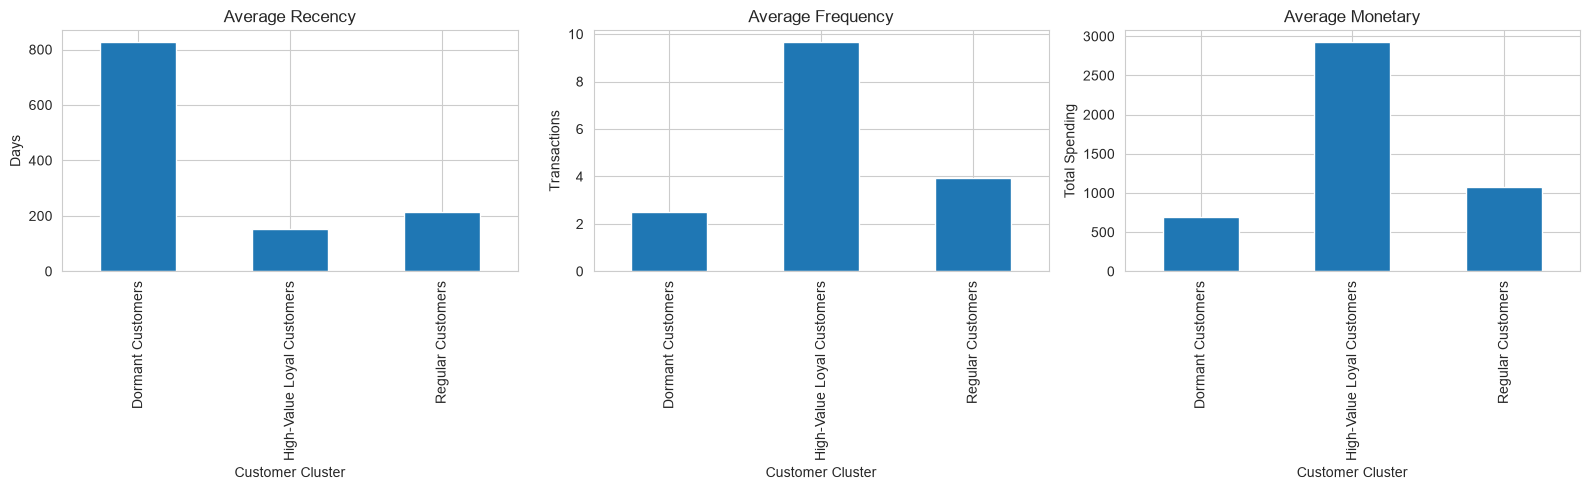

In [25]:
# create 2 comparison charts

fig, axes = plt.subplots(1, 3, figsize = (16, 5))

# recency comparison
cluster_profile["Recency"].plot(
    kind = "bar", ax = axes[0], title = "Average Recency"
)
axes[0].set_ylabel("Days")
axes[0].set_xlabel("Customer Cluster")

# frequency comparison
cluster_profile["Frequency"].plot(
    kind="bar", ax=axes[1], title="Average Frequency"
)
axes[1].set_ylabel("Transactions")
axes[1].set_xlabel("Customer Cluster")

# monetary comparison
cluster_profile["Monetary"].plot(
    kind="bar", ax=axes[2], title="Average Monetary"
)
axes[2].set_ylabel("Total Spending")
axes[2].set_xlabel("Customer Cluster")

plt.tight_layout()
plt.savefig(
    r"D:\Customer Segmentation Analysis\outputs\figures\kmeans_cluster_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [26]:
# Save cluster summary

cluster_profile.to_csv(
    r"D:\Customer Segmentation Analysis\outputs\reports\kmeans_cluster_summary.csv"
)

print("K-Means cluster summary saved successfully.")

K-Means cluster summary saved successfully.


In [27]:
# compare RFM and k-means segments

comparison = pd.crosstab(
    rfm["Customer_Segment"],
    rfm["Cluster_Name"]
)

print("RFM vs K-Means Comparison: ")
print(comparison)

RFM vs K-Means Comparison: 
Cluster_Name         Dormant Customers  High-Value Loyal Customers  \
Customer_Segment                                                     
At Risk                            146                           3   
Champions                            0                        1021   
Hibernating                        937                           0   
Loyal Customers                     65                         643   
Potential Loyalists                  0                           8   
Recent Customers                     0                           0   

Cluster_Name         Regular Customers  
Customer_Segment                        
At Risk                            383  
Champions                          203  
Hibernating                        503  
Loyal Customers                    494  
Potential Loyalists               1192  
Recent Customers                   634  


In [28]:
# calculate percentage distribution across k-means clusters

comparison_percentage = comparison.div(
    comparison.sum(axis = 1),
    axis = 0
) * 100

print("Percentage Comparison: ")
print(comparison_percentage.round(2))

Percentage Comparison: 
Cluster_Name         Dormant Customers  High-Value Loyal Customers  \
Customer_Segment                                                     
At Risk                          27.44                        0.56   
Champions                         0.00                       83.42   
Hibernating                      65.07                        0.00   
Loyal Customers                   5.41                       53.49   
Potential Loyalists               0.00                        0.67   
Recent Customers                  0.00                        0.00   

Cluster_Name         Regular Customers  
Customer_Segment                        
At Risk                          71.99  
Champions                        16.58  
Hibernating                      34.93  
Loyal Customers                  41.10  
Potential Loyalists              99.33  
Recent Customers                100.00  


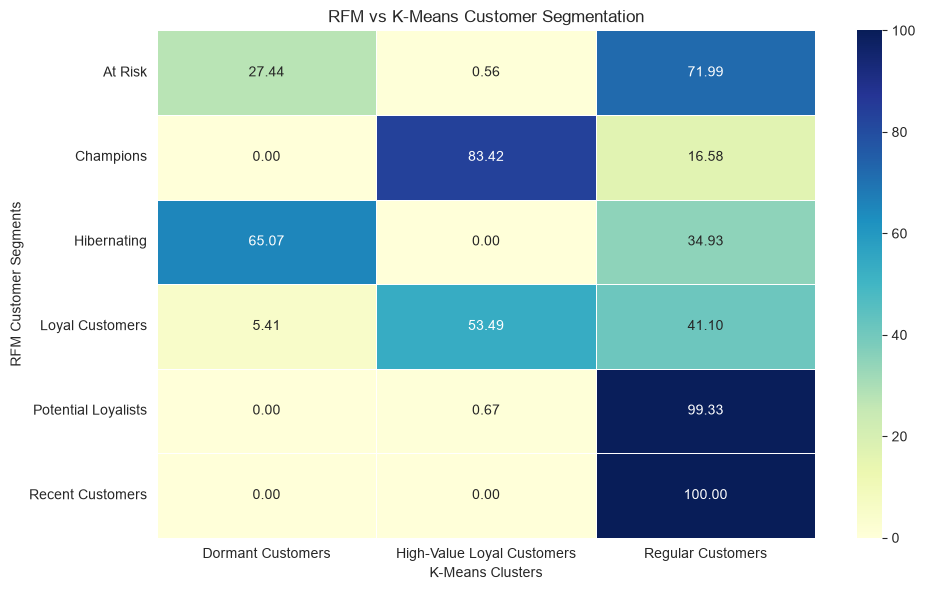

In [30]:
# comparison heatman

plt.figure(figsize=(10, 6))

sns.heatmap(
    comparison_percentage,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("RFM vs K-Means Customer Segmentation")
plt.xlabel("K-Means Clusters")
plt.ylabel("RFM Customer Segments")

plt.tight_layout()
plt.savefig(
    r"D:\Customer Segmentation Analysis\outputs\figures\rfm_vs_kmeans_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [31]:
transactions = pd.read_csv(
    r"D:\Customer Segmentation Analysis\data\processed\transactions_cleaned.csv"
)

print(transactions.head())

  TransactionID CustomerID   OrderDate ProductID  Quantity  UnitPrice  \
0       T004738     C00837  2021-01-04      P004         4     127.04   
1       T017137     C00700  2021-01-04      P003         1     155.25   
2       T007957     C05879  2021-01-06      P010         2      83.82   
3       T014421     C01707  2021-01-06      P003         1     155.25   
4       T010989     C04394  2021-01-07      P018         3      16.17   

   Discount   Sales  Profit  
0      0.15  431.94  226.28  
1      0.15  131.96   54.07  
2      0.05  159.26   59.54  
3      0.15  131.96   63.44  
4      0.00   48.51   23.66  


In [32]:
# calculate revenue and profit

customer_performance = transactions.groupby("CustomerID").agg(
    Total_Revenue = ("Sales", "sum"),
    Total_Profit = ("Profit", "sum"),
    Total_Transactions = ("TransactionID", "nunique")
).reset_index()

print(customer_performance.head())

  CustomerID  Total_Revenue  Total_Profit  Total_Transactions
0     C00001        1708.39        598.02                   4
1     C00002        1121.89        268.94                   5
2     C00003         761.39        238.15                   2
3     C00004        1362.58        489.05                   5
4     C00005        1472.60        377.63                   3


In [34]:
# merge customer performance wit cluster information

rfm = rfm.merge(
    customer_performance,
    on = "CustomerID",
    how = "left"
)

print(rfm.head())

  CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0     C00001      468          4   1708.39        2        2        4   
1     C00002      601          5   1121.89        1        3        3   
2     C00003       76          2    761.39        4        1        2   
3     C00004       80          5   1362.58        4        3        3   
4     C00005      325          3   1472.60        2        2        3   

   RFM_Score     Customer_Segment  Cluster       Cluster_Name  Total_Revenue  \
0        224          Hibernating        1  Regular Customers        1708.39   
1        133              At Risk        0  Dormant Customers        1121.89   
2        412     Recent Customers        1  Regular Customers         761.39   
3        433  Potential Loyalists        1  Regular Customers        1362.58   
4        223          Hibernating        1  Regular Customers        1472.60   

   Total_Profit  Total_Transactions  
0        598.02                   4  
1   

In [35]:
# calculate business performance by cluster

cluster_business_summary = rfm.groupby("Cluster_Name").agg(
    Customer_Count = ("CustomerID", "count"),
    Total_Revenue = ("Total_Revenue", "sum"),
    Average_Revenue = ("Total_Revenue", "mean"),
    Total_profit = ("Total_Profit", "sum"),
    Average_Profit = ("Total_Profit", "mean")
).round(2)

print(cluster_business_summary)

                            Customer_Count  Total_Revenue  Average_Revenue  \
Cluster_Name                                                                 
Dormant Customers                     1148      797525.57           694.71   
High-Value Loyal Customers            1675     4904315.39          2927.95   
Regular Customers                     3409     3668617.98          1076.16   

                            Total_profit  Average_Profit  
Cluster_Name                                              
Dormant Customers              294627.78          256.64  
High-Value Loyal Customers    1784622.12         1065.45  
Regular Customers             1340459.37          393.21  


In [36]:
cluster_business_summary.to_csv(
    r"D:\Customer Segmentation Analysis\outputs\reports\cluster_business_summary.csv"
)

print("Business summary saved successfully.")

Business summary saved successfully.


In [3]:
# Save final customer segmentation data

rfm.to_csv(
    r"D:\Customer Segmentation Analysis\outputs\processed_data\final_customer_segmentation.csv",
    index=False
)

print("Final customer segmentation data saved successfully.")
print("Dataset shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())

Final customer segmentation data saved successfully.
Dataset shape: (6232, 9)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment']


In [4]:
print(rfm.columns.tolist())

['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment']


In [5]:
rfm = pd.read_csv(
    r"D:\Customer Segmentation Analysis\data\processed\customer_kmeans_segments.csv"
)

print("Dataset shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())

Dataset shape: (6232, 11)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment', 'Cluster', 'Cluster_Name']


In [6]:
# Load cleaned transactions
transactions = pd.read_csv(
    r"D:\Customer Segmentation Analysis\data\processed\transactions_cleaned.csv"
)

# Calculate customer level business performance
customer_performance = transactions.groupby("CustomerID").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Transactions=("TransactionID", "nunique")
).reset_index()

# Merge with customer segmentation data
rfm = rfm.merge(
    customer_performance,
    on="CustomerID",
    how="left"
)

print("Dataset shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())

Dataset shape: (6232, 14)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment', 'Cluster', 'Cluster_Name', 'Total_Revenue', 'Total_Profit', 'Total_Transactions']


In [7]:
import os

output_folder = r"D:\Customer Segmentation Analysis\outputs\processed_data"

os.makedirs(output_folder, exist_ok=True)

rfm.to_csv(
    os.path.join(output_folder, "final_customer_segmentation.csv"),
    index=False
)
print("Final dataset exported successfully!")
print("Dataset shape:", rfm.shape)

Final dataset exported successfully!
Dataset shape: (6232, 14)
